# Topological Centrality vs. Empirical Traffic Flow in the NRW Motorway Network

## Overview
This project is part of my Master's thesis and investigates the relationship between **topological network centrality** and **actual empirical traffic volume** across the motorway network of North Rhine-Westphalia (NRW), Germany.

Using OpenStreetMap (OSM) graph data and minute-by-minute loop detector measurements from 2016/2017, we evaluate whether a purely structural network metric (shortest-path betweenness of motorway junctions) can accurately reflect real-world traffic loads, and how spatial constraints (e.g., filtering for long-distance routes) affect this correlation.

In [1]:
import sys
from pathlib import Path
import pandas as pd

# Add project root to Python path to enable imports from 'src'
sys.path.append(str(Path.cwd().parent))

from src import functions as f
from src import plots as p
from src.centrality_analysis import centrality_analysis

## 1. Data Loading & Methodology

The underlying calculation performs an all-pairs shortest-path routing (Dijkstra's algorithm weighted by `travel_time`) between all motorway junctions in NRW and maps the resulting paths onto physical loop detector locations.

* **Travel Time Calculation:** For each road segment (edge), the theoretical `travel_time` is derived from the segment's geometric length divided by the applicable speed limit (`maxspeed`) or, where unrestricted, the German motorway advisory speed (*Richtgeschwindigkeit*).
* **Traffic Flow Aggregation:** Next, the algorithm aggregates a full year of empirical traffic flow data ($Q_i$ in vehicles/minute) from an HDF5 database:
  $$Q_i = \frac{1}{T_i}\sum_t q_i(t)$$
  where $T_i$ denotes the total number of valid measurement intervals recorded by detector $i$.

Because the full routing and time-series aggregation (`centrality_analysis()`) is computationally intensive, we load the pre-computed dataset from `data/sample_results.parquet` for this showcase.

In [3]:
# Load the NRW motorway network graph
G = f.import_network(network_path="../data/nrw_detector.graphml")

# Load pre-computed results for df = centrality_analysis(min_dist_km=30, G=G, hdf5_path="../data/DetektorDaten.h5")
df = pd.read_parquet("../data/sample_results.parquet")
df.head()

,node_id,centrality,centrality_dist,traffic_volume,measurements_count
0,936000000,1242,1201,15.103809,478176
1,1016000000,4442,4399,27.273600,486264
2,920000000,4756,4750,27.852985,486630
3,956000000,6221,6281,26.070967,487901
4,957000000,6221,6281,26.067254,488610


## 2. Spatial Distribution on the NRW Network

First, we visualize the calculated metrics on the NRW motorway graph (filtered for driving direction North-East `NO`):
1. **Standard Centrality ($\tilde{Z}_i$):** Counts how often a detector lies on the shortest path between any two junctions, normalized by the mean.
2. **Long-Distance Centrality ($\tilde{Z}_i^{\mathrm{(Dist)}}$):** Only considers routes between junctions that are at least $30\text{ km}$ apart, reducing distortion from dense urban junction clusters (e.g., in the Ruhr area).
3. **Empirical Traffic Flow ($Q_i$):** The actual measured average traffic volume in vehicles per minute.

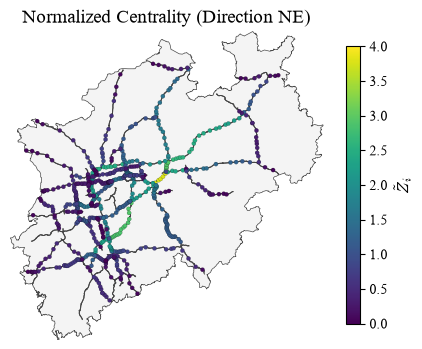

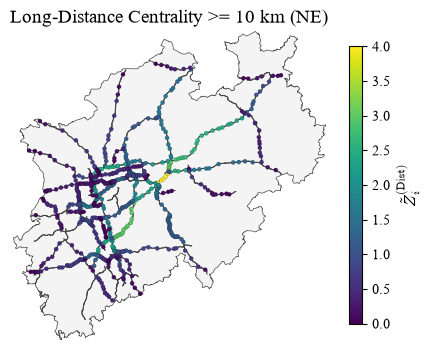

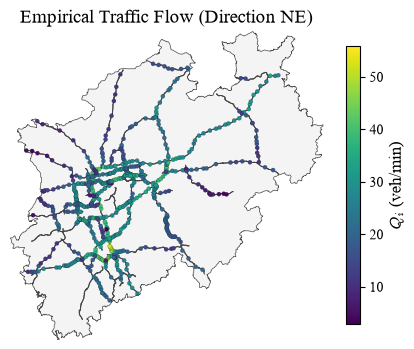

In [4]:
# 1. Normalized Topological Centrality
p.plot_network_metric(
    df_detectors=df,
    G=G,
    direction="NO",
    metric_col="centrality",
    labels={"title": "Normalized Centrality (Direction NE)", "cbar": r"$\tilde{Z}_i$"},
    filename="map_centrality_norm.pdf",
    output_dir="../images",
    normalized=True
)

# 2. Long-Distance Centrality (>= 30 km)
p.plot_network_metric(
    df_detectors=df,
    G=G,
    direction="NO",
    metric_col="centrality_dist",
    labels={"title": "Long-Distance Centrality >= 10 km (NE)", "cbar": r"$\tilde{Z}_i^{\mathrm{(Dist)}}$"},
    filename="map_centrality_dist.pdf",
    output_dir="../images",
    normalized=True
)

# 3. Empirical Traffic Volume
p.plot_network_metric(
    df_detectors=df,
    G=G,
    direction="NO",
    metric_col="traffic_volume",
    labels={"title": "Empirical Traffic Flow (Direction NE)", "cbar": r"$Q_i$ (veh/min)"},
    filename="map_traffic_volume.pdf",
    output_dir="../images",
    normalized=False
)

## 3. Correlation Analysis

To quantify how well the topological structure explains real-world traffic flow, we compute the Pearson correlation coefficient and inspect the joint distributions via scatter plots.

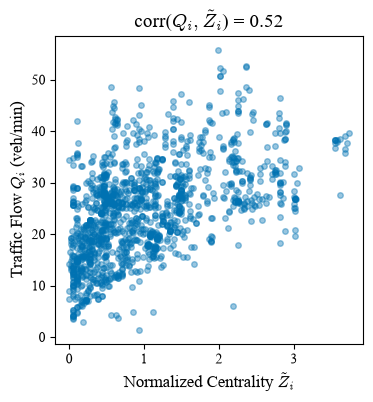

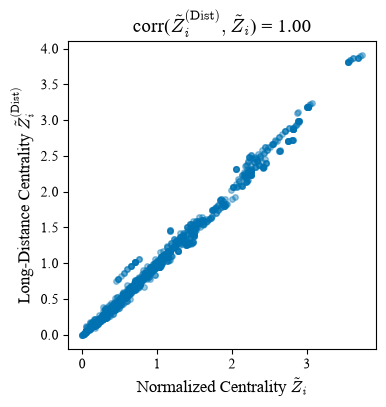

In [5]:
# Correlation 1: Standard Centrality vs. Empirical Traffic Flow
p.plot_metric_correlation(
    df=df,
    x_col="centrality",
    y_col="traffic_volume",
    norm_x=True,
    norm_y=False,
    labels={
        "xlabel": r"Normalized Centrality $\tilde{Z}_i$",
        "ylabel": r"Traffic Flow $Q_i$ (veh/min)",
        "corr_vars": r"Q_i, \tilde{Z}_i"
    },
    filename="scatter_centrality_vs_traffic.pdf",
    output_dir="../images"
)

# Correlation 2: Standard Centrality vs. Long-Distance Centrality
p.plot_metric_correlation(
    df=df,
    x_col="centrality",
    y_col="centrality_dist",
    norm_x=True,
    norm_y=True,
    labels={
        "xlabel": r"Normalized Centrality $\tilde{Z}_i$",
        "ylabel": r"Long-Distance Centrality $\tilde{Z}_i^{\mathrm{(Dist)}}$",
        "corr_vars": r"\tilde{Z}_i^{\mathrm{(Dist)}}, \tilde{Z}_i"
    },
    filename="scatter_centrality_vs_dist.pdf",
    output_dir="../images"
)

## 4. Key Takeaways

* **Significant Baseline Correlation ($r = 0.52$):** There is a moderate linear correlation between pure topological centrality and empirical traffic flow. Notably, this relationship is achieved using only the network graph, without incorporating external data such as population density, subordinate road networks, lane counts, or time-of-day splits.
* **High Centrality vs. Parallel Relief Routes:** High centrality (such as along the SW–NE diagonal of the A1 motorway) reliably indicates high real-world traffic volume. Conversely, low centrality does not necessarily imply low traffic: in dense urban areas, shortest-path routing concentrates the theoretical load onto a single primary motorway, whereas actual traffic distributes more evenly across parallel relief routes.
* **Boundary Effects:** Motorways near the state borders exhibit lower centrality because the routing is restricted to junctions within NRW. However, since both the highest network density and the most populated metropolitan areas are located centrally within the state, these boundary effects have minimal impact on the core network.
* **Intrinsic Network Stability ($\ge 30\text{ km}$ Filter):** Excluding short-distance routes ($< 30\text{ km}$) yields virtually identical centrality distributions. This robustness demonstrates that socio-spatial factors (like population density and regional connectivity) are already implicitly encoded in the structural layout of the motorway network itself—making pure topology a sufficient proxy for identifying critical traffic corridors.